In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import OPTICS
from sklearn.cluster import AgglomerativeClustering
from statsmodels.tsa.stattools import coint
from statsmodels.api import OLS, add_constant
from spectral_pair_selector import (
    SpectralClusterConfig,
    SpectralPairSelector,
    find_ml_pairs_spectral,
)

# --- SETUP ---
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

DATA_PROCESSED = project_root / "data_processed"
N_COMPONENTS = 20
plt.style.use('bmh')
print(f"Project Root: {project_root}")

Project Root: c:\Users\sanka\OneDrive\Documents\MMU\ML STATISTICAL ARBITRAGE


In [2]:
import os

OUTPUT_DIR = "results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
def estimate_half_life(spread):

    spread = spread.dropna()

    lagged = spread.shift(1).dropna()
    delta = spread.diff().dropna()

    lagged = lagged.loc[delta.index]

    model = OLS(
        delta,
        add_constant(lagged)
    ).fit()

    beta = model.params.iloc[1]

    if beta >= 0:
        return np.inf

    half_life = -np.log(2) / beta

    return float(half_life)

In [4]:
def estimate_hedge_ratio(price1, price2):
    """
    Estimate static hedge ratio using OLS.

    log(price1) = alpha + beta * log(price2)
    """

    log1 = np.log(price1)
    log2 = np.log(price2)

    X = add_constant(log2)

    model = OLS(log1, X).fit()

    beta = model.params.iloc[1]

    return float(beta)

In [5]:
def load_market_data(market_prefix, cohort_type):
    """
    Load returns and prices together.
    """

    if cohort_type == "broad":
        return_file = f"{market_prefix}_2015_returns.parquet"
        price_file  = f"{market_prefix}_2015_prices.parquet"
        label = f"{market_prefix.upper()} Broad (2015–2026)"
    else:
        return_file = f"{market_prefix}_returns.parquet"
        price_file  = f"{market_prefix}_prices.parquet"
        label = f"{market_prefix.upper()} Long (2007–2026)"

    returns = pd.read_parquet(DATA_PROCESSED / return_file)
    prices = pd.read_parquet(DATA_PROCESSED / price_file)

    # Drop stocks with too many missing returns
    returns = returns.dropna(
        axis=1,
        thresh=int(0.90 * len(returns))
    )

    # Warn if returns contain stocks missing from prices
    missing_prices = returns.columns.difference(prices.columns)

    if len(missing_prices):
        print(f"Warning: {len(missing_prices)} stocks missing from prices:")
        print(sorted(missing_prices))

    # Keep only stocks present in BOTH datasets
    common = returns.columns.intersection(prices.columns)

    returns = returns[common]
    prices = prices[common]

    print(
        f"Loaded {label}: "
        f"{returns.shape[0]} Days × "
        f"{returns.shape[1]} Stocks"
    )

    return returns, prices, label

In [38]:
def find_ml_pairs_optics(returns_df, prices_df, min_samples=5):
    """
    1. Calculate PCA Residuals (Remove Market Factor).
    2. Cluster the residuals using OPTICS.
    """
    # --- Step A: Get PCA Residuals ---
    # Remove poor-quality stocks
    clean = returns_df.dropna(axis=0)

    # Standardize returns
    scaler = StandardScaler()
    scaled = scaler.fit_transform(clean)

    # Remove common factors
    pca = PCA(
        n_components=N_COMPONENTS,
        random_state=42)
    factors = pca.fit_transform(scaled)
    print("\n===== PCA Explained Variance =====")
    print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.4f}")
    print("Explained variance by component:")
    print(pca.explained_variance_ratio_)
    market_component = pca.inverse_transform(factors)
    market_component = scaler.inverse_transform(
        market_component)
    market_component = pd.DataFrame(
        market_component,
        index=clean.index,
        columns=clean.columns)
    residuals_df = clean - market_component
    
    # --- Step B: Clustering ---
    # Calculate distance matrix (1 - correlation)
    corr_matrix = residuals_df.corr()
    # ===== Residual Correlation Statistics =====
    corr_values = corr_matrix.values[np.triu_indices_from(corr_matrix, k=1)]

    print("\n===== Residual Correlation Statistics =====")
    print(f"Mean correlation  : {corr_values.mean():.4f}")
    print(f"Median correlation: {np.median(corr_values):.4f}")
    print(f"Std correlation   : {corr_values.std():.4f}")
    print(f"Min correlation   : {corr_values.min():.4f}")
    print(f"Max correlation   : {corr_values.max():.4f}")
    
    distance_matrix = np.sqrt(2 * (1 - corr_matrix))
    distance_matrix = distance_matrix.fillna(2) # Handle rare NaNs
    
    # ===== Distance Matrix Statistics =====
    print("\n===== Distance Matrix Statistics =====")
    print(f"Min   : {distance_matrix.values.min():.4f}")
    print(f"Max   : {distance_matrix.values.max():.4f}")
    print(f"Mean  : {distance_matrix.values.mean():.4f}")
    print(f"Median: {np.median(distance_matrix.values):.4f}")
    print(f"Std   : {distance_matrix.values.std():.4f}")
    
    # Run OPTICS Clustering
    # min_samples=3 means a cluster must have at least 3 similar stocks
    clustering = OPTICS(min_samples=min_samples,xi=0.05,
                        min_cluster_size=0.02, metric='precomputed')
    clustering.fit(distance_matrix)
    
    labels = clustering.labels_
    print("\n===== OPTICS Reachability =====")
    print("First 20 reachability values:")
    print(clustering.reachability_[:20])

    print("\nFirst 20 ordering values:")
    print(clustering.ordering_[:20])

    print(f"\nFinite core distances: "
          f"{np.isfinite(clustering.core_distances_).sum()} / "
          f"{len(clustering.core_distances_)}")
    print("\n===== OPTICS Diagnostics =====")
    print("Unique labels:", np.unique(labels))

    for lbl in np.unique(labels):
        print(f"Label {lbl}: {(labels == lbl).sum()} stocks")
    results = pd.DataFrame({
        "Ticker": clean.columns,
        "Cluster": labels })
    clusters = results[results["Cluster"] != -1].copy()
    filtered_rows = []
    for cluster_id in sorted(clusters["Cluster"].unique()):
        cluster_members = clusters.loc[
            clusters["Cluster"] == cluster_id,
            "Ticker"
            ].tolist()
        if len(cluster_members) < 2:
            continue
        print(f"\nProcessing Cluster {cluster_id} ({len(cluster_members)} stocks)")
        accepted_pairs = []
        total_pairs = len(cluster_members) * (len(cluster_members) - 1) // 2
        print(f"  Testing {total_pairs} candidate pairs...")
        
        for i in range(len(cluster_members)):
            for j in range(i + 1, len(cluster_members)):
                t1 = cluster_members[i]
                t2 = cluster_members[j]    
                    
                try:
                    # IMPORTANT:
                    # # Cointegration uses PRICE DATA
                    pair_prices = prices_df[[t1, t2]].dropna()
                    if len(pair_prices) < 252:
                        continue
                    _, pvalue, _ = coint(
                        pair_prices.iloc[:, 0],
                        pair_prices.iloc[:, 1],
                        autolag=None,
                        maxlag=2
                        )
                    
                    if pvalue < 0.05:
                        beta = estimate_hedge_ratio(
                            pair_prices.iloc[:,0],
                            pair_prices.iloc[:,1])
                        spread = (np.log(pair_prices.iloc[:,0])
                                  - beta * np.log(pair_prices.iloc[:,1]))
                        half_life = estimate_half_life(spread)
                        corr = pair_prices.iloc[:,0].corr(
                            pair_prices.iloc[:,1])
                        spread_vol = spread.std()
                        if 2 <= half_life <= 60:
                            ticker1, ticker2 = sorted([t1, t2])
                            accepted_pairs.append({
                                "Cluster_ID": cluster_id,
                                "Ticker1": ticker1,
                                "Ticker2": ticker2,
                                "Correlation": corr,
                                "CointegrationPValue": pvalue,
                                "HalfLife": half_life,
                                "HedgeRatio": beta,
                                "SpreadVolatility": spread_vol
                            })
                        
                except Exception:
                    continue
            
        filtered_rows.extend(accepted_pairs) 
        print(f"  Accepted {len(accepted_pairs)} tradable pairs.")      
    
    pairs = (
        pd.DataFrame(filtered_rows)
        .drop_duplicates(
            subset=["Cluster_ID", "Ticker1", "Ticker2"]
            )
    )

    if pairs.empty:
        return pairs

    return (
        pairs
        .sort_values(["Cluster_ID", "Ticker1", "Ticker2"])
        .reset_index(drop=True))

In [39]:
def analyze_market(market_prefix, market_name):
    print(f"\n{'='*20} ANALYZING {market_name} {'='*20}")

    for cohort in ['long', 'broad']:

        # 1. Load Data
        returns_df, prices_df, label = load_market_data(
            market_prefix,
            cohort
        )

        if returns_df is None or prices_df is None:
            continue

        # 2. Find Pairs
        pairs_df = find_ml_pairs_optics(
            returns_df,
            prices_df,
            min_samples=5
        )

        if pairs_df.empty:
            print(f"{label}: No valid pairs found.")
            continue

        # ==========================
        # SAVE OPTICS RESULTS
        # ==========================
        if market_prefix == "nifty500":
            market_tag = "nifty"
        elif market_prefix == "sp500":
            market_tag = "sp500"
        else:
            market_tag = market_prefix

        output_file = f"optics_{market_tag}_{cohort}.csv"

        pairs_df.to_csv(
            os.path.join(OUTPUT_DIR, output_file),
            index=False
        )

        print(f"OPTICS results saved to: {output_file}")

        # ==========================
        # REPORT RESULTS
        # ==========================
        n_clusters = pairs_df["Cluster_ID"].nunique()

        unique_stocks = len(
            set(pairs_df["Ticker1"]) |
            set(pairs_df["Ticker2"])
        )

        n_pairs = len(pairs_df)

        print(f"\n--- Results for {label} ---")
        print(
            f"Found {n_clusters} clusters, "
            f"{unique_stocks} unique stocks, "
            f"and {n_pairs} tradable pairs."
        )

        if n_clusters > 0:
            print("Example Pairs:")

            for c in sorted(pairs_df["Cluster_ID"].unique()):

                cluster_pairs = pairs_df[
                    pairs_df["Cluster_ID"] == c
                ]

                members = sorted(
                    set(cluster_pairs["Ticker1"]) |
                    set(cluster_pairs["Ticker2"])
                )

                print(f"  Cluster {c}: {members}")
        else:
            print("No significant pairs found with current settings.")


# EXECUTE
analyze_market("nifty500", "NIFTY 500")
analyze_market("sp500", "S&P 500")


==================== ANALYZING NIFTY 500 ====================
Loaded NIFTY500 Long (2007–2026): 4691 Days × 278 Stocks

===== PCA Explained Variance =====
Total explained variance: 0.3804
Explained variance by component:
[0.23015426 0.01864701 0.0157154  0.01176593 0.01016028 0.00963105
 0.0082936  0.00808198 0.00698031 0.00668329 0.00616208 0.0058514
 0.00569838 0.00566693 0.00556234 0.00545266 0.00528657 0.00490785
 0.00489671 0.00479909]

===== Residual Correlation Statistics =====
Mean correlation  : -0.0035
Median correlation: -0.0030
Std correlation   : 0.0276
Min correlation   : -0.4968
Max correlation   : 0.5616

===== Distance Matrix Statistics =====
Min   : 0.0000
Max   : 1.7302
Mean  : 1.4115
Median: 1.4162
Std   : 0.0870

===== OPTICS Reachability =====
First 20 reachability values:
[       inf 1.37437649 1.35496453 1.36620479 1.38377912 1.36874504
 1.37731429 1.36913317 1.37269829 1.37790066 1.36790666 1.37292832
 1.36030294 1.37909835 1.35523392 1.37920034 1.3706993  1.3

In [36]:
def find_ml_pairs_agglomerative(
    returns_df,
    prices_df,
    distance_threshold=1.55
):
    """
    1. Calculate PCA Residuals (Remove Market Factor).
    2. Cluster the residuals using Agglomerative Clustering.
    """
    # --- Step A: Get PCA Residuals ---
    # Remove poor-quality stocks
    clean = returns_df.dropna(axis=0)

    # Standardize returns
    scaler = StandardScaler()
    scaled = scaler.fit_transform(clean)

    # Remove common factors
    pca = PCA(
        n_components=N_COMPONENTS,
        random_state=42)
    factors = pca.fit_transform(scaled)
    print("\n===== PCA Explained Variance =====")
    print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.4f}")
    print("Explained variance by component:")
    print(pca.explained_variance_ratio_)
    market_component = pca.inverse_transform(factors)
    market_component = scaler.inverse_transform(
        market_component)
    market_component = pd.DataFrame(
        market_component,
        index=clean.index,
        columns=clean.columns)
    residuals_df = clean - market_component

    # --- Step B: Agglomerative Clustering ---
    # Calculate distance matrix (1 - correlation)
    corr_matrix = residuals_df.corr()

    # ===== Residual Correlation Statistics =====
    corr_values = corr_matrix.values[np.triu_indices_from(corr_matrix, k=1)]

    print("\n===== Residual Correlation Statistics =====")
    print(f"Mean correlation  : {corr_values.mean():.4f}")
    print(f"Median correlation: {np.median(corr_values):.4f}")
    print(f"Std correlation   : {corr_values.std():.4f}")
    print(f"Min correlation   : {corr_values.min():.4f}")
    print(f"Max correlation   : {corr_values.max():.4f}")

    distance_matrix = np.sqrt(2 * (1 - corr_matrix))
    distance_matrix = distance_matrix.fillna(2)  # Handle rare NaNs

    # ===== Distance Matrix Statistics =====
    print("\n===== Distance Matrix Statistics =====")
    print(f"Min   : {distance_matrix.values.min():.4f}")
    print(f"Max   : {distance_matrix.values.max():.4f}")
    print(f"Mean  : {distance_matrix.values.mean():.4f}")
    print(f"Median: {np.median(distance_matrix.values):.4f}")
    print(f"Std   : {distance_matrix.values.std():.4f}")

    # Run Agglomerative Clustering
    clustering = AgglomerativeClustering(
        metric="precomputed",
        linkage="complete",
        distance_threshold=distance_threshold,
        n_clusters=None
    )

    labels = clustering.fit_predict(distance_matrix)

    print("\n===== Agglomerative Diagnostics =====")
    print("\n===== Agglomerative Diagnostics =====")
    print(f"Total clusters found: {len(np.unique(labels))}")
    print("Cluster labels:", np.unique(labels))
    

    for lbl in np.unique(labels):
        print(f"Label {lbl}: {(labels == lbl).sum()} stocks")

    results = pd.DataFrame({
        "Ticker": clean.columns,
        "Cluster": labels
    })

    clusters = results

    filtered_rows = []

    for cluster_id in sorted(clusters["Cluster"].unique()):
        cluster_members = clusters.loc[
            clusters["Cluster"] == cluster_id,
            "Ticker"
        ].tolist()

        if len(cluster_members) < 2:
            continue

        print(f"\nProcessing Cluster {cluster_id} ({len(cluster_members)} stocks)")

        accepted_pairs = []

        total_pairs = len(cluster_members) * (len(cluster_members) - 1) // 2
        print(f"  Testing {total_pairs} candidate pairs...")

        for i in range(len(cluster_members)):
            for j in range(i + 1, len(cluster_members)):
                t1 = cluster_members[i]
                t2 = cluster_members[j]

                try:
                    # IMPORTANT:
                    # Cointegration uses PRICE DATA
                    pair_prices = prices_df[[t1, t2]].dropna()

                    if len(pair_prices) < 252:
                        continue

                    _, pvalue, _ = coint(
                        pair_prices.iloc[:, 0],
                        pair_prices.iloc[:, 1],
                        autolag=None,
                        maxlag=2
                    )

                    if pvalue < 0.05:
                        beta = estimate_hedge_ratio(
                            pair_prices.iloc[:, 0],
                            pair_prices.iloc[:, 1]
                        )

                        spread = (
                            np.log(pair_prices.iloc[:, 0])
                            - beta * np.log(pair_prices.iloc[:, 1])
                        )

                        half_life = estimate_half_life(spread)

                        corr = pair_prices.iloc[:, 0].corr(
                            pair_prices.iloc[:, 1]
                        )

                        spread_vol = spread.std()

                        if 2 <= half_life <= 60:
                            ticker1, ticker2 = sorted([t1, t2])

                            accepted_pairs.append({
                                "Cluster_ID": cluster_id,
                                "Ticker1": ticker1,
                                "Ticker2": ticker2,
                                "Correlation": corr,
                                "CointegrationPValue": pvalue,
                                "HalfLife": half_life,
                                "HedgeRatio": beta,
                                "SpreadVolatility": spread_vol
                            })

                except Exception:
                    continue

        filtered_rows.extend(accepted_pairs)

        print(f"  Accepted {len(accepted_pairs)} tradable pairs.")

    pairs = (
        pd.DataFrame(filtered_rows)
        .drop_duplicates(
            subset=["Cluster_ID", "Ticker1", "Ticker2"]
        )
    )

    if pairs.empty:
        return pairs

    return (
        pairs
        .sort_values(["Cluster_ID", "Ticker1", "Ticker2"])
        .reset_index(drop=True)
    )

In [37]:
def analyze_market(market_prefix, market_name):
    print(f"\n{'='*20} ANALYZING {market_name} {'='*20}")

    for cohort in ['long', 'broad']:
        # 1. Load Data
        returns_df, prices_df, label = load_market_data(
            market_prefix,
            cohort)
        if returns_df is None or prices_df is None:
            continue

        # 2. Find Pairs
        pairs_df = find_ml_pairs_agglomerative(
            returns_df,
            prices_df,
            distance_threshold=1.55)
        if pairs_df.empty:
            print(f"{label}: No valid pairs found.")
            continue

        # Save Agglomerative results
        if market_prefix == "nifty500":
            market_tag = "nifty"
        elif market_prefix == "sp500":
            market_tag = "sp500"
        else:
            market_tag = market_prefix

        output_file = f"agglo_{market_tag}_{cohort}_155.csv"
        pairs_df.to_csv(os.path.join(OUTPUT_DIR, output_file), index=False)
        print(f"Agglomerative results saved to: {output_file}")

        # 3. Report Results
        n_clusters = pairs_df['Cluster_ID'].nunique()
        unique_stocks = len(
            set(pairs_df["Ticker1"]) |
            set(pairs_df["Ticker2"]))
        n_pairs = len(pairs_df)

        print(f"\n--- Results for {label} ---")
        print(
            f"Found {n_clusters} clusters, "
            f"{unique_stocks} unique stocks, "
            f"and {n_pairs} tradable pairs."
        )

        # Show top 3 clusters as examples
        if n_clusters > 0:
            print("Example Pairs:")
            for c in sorted(pairs_df['Cluster_ID'].unique()):
                cluster_pairs = pairs_df[
                    pairs_df["Cluster_ID"] == c
                ]
                members = sorted(
                    set(cluster_pairs["Ticker1"])
                    |
                    set(cluster_pairs["Ticker2"])
                )
                print(f"  Cluster {c}: {members}")
        else:
            print("  No significant pairs found with current settings.")

# --- EXECUTE ---
analyze_market("nifty500", "NIFTY 500")
analyze_market("sp500", "S&P 500")


==================== ANALYZING NIFTY 500 ====================
Loaded NIFTY500 Long (2007–2026): 4691 Days × 278 Stocks

===== PCA Explained Variance =====
Total explained variance: 0.3804
Explained variance by component:
[0.23015426 0.01864701 0.0157154  0.01176593 0.01016028 0.00963105
 0.0082936  0.00808198 0.00698031 0.00668329 0.00616208 0.0058514
 0.00569838 0.00566693 0.00556234 0.00545266 0.00528657 0.00490785
 0.00489671 0.00479909]

===== Residual Correlation Statistics =====
Mean correlation  : -0.0035
Median correlation: -0.0030
Std correlation   : 0.0276
Min correlation   : -0.4968
Max correlation   : 0.5616

===== Distance Matrix Statistics =====
Min   : 0.0000
Max   : 1.7302
Mean  : 1.4115
Median: 1.4162
Std   : 0.0870

===== Agglomerative Diagnostics =====

===== Agglomerative Diagnostics =====
Total clusters found: 2
Cluster labels: [0 1]
Label 0: 129 stocks
Label 1: 149 stocks

Processing Cluster 0 (129 stocks)
  Testing 8256 candidate pairs...
  Accepted 4 tradable p

In [6]:
import pandas as pd
from pathlib import Path

# ============================================================
# CHANGE ONLY THIS
# ============================================================
ALGORITHM = "spectral"      # "agglo" or "optics" or "spectral"

# ============================================================

RESULTS_DIR = Path("results")
OUTPUT_DIR = Path("data_processed")
OUTPUT_DIR.mkdir(exist_ok=True)

files = [
    ("nifty500", "long"),
    ("nifty500", "broad"),
    ("sp500", "long"),
    ("sp500", "broad"),
]

dfs = []

for market, cohort in files:

    if market == "nifty500":
        tag = "nifty"
        market_name = "NIFTY 500"
    else:
        tag = "sp500"
        market_name = "S&P 500"

    if ALGORITHM == "agglo":
        filename = f"agglo_{tag}_{cohort}_150.csv"
    elif ALGORITHM == "optics":
        filename = f"optics_{tag}_{cohort}.csv"
    elif ALGORITHM == "spectral":
        filename = f"spectral_{tag}_{cohort}.csv"
    else:
        raise ValueError(f"Unknown algorithm: {ALGORITHM}")

    path = RESULTS_DIR / filename

    print(f"Loading {path}")

    df = pd.read_csv(path)

    # Add identifiers expected by backtester
    df["Market"] = market_name
    df["Cohort"] = cohort

    dfs.append(df)

all_pairs = (
    pd.concat(dfs, ignore_index=True)
      .sort_values(["Market", "Cohort", "Cluster_ID"])
      .reset_index(drop=True)
)

output_file = OUTPUT_DIR / f"all_ml_pairs_{ALGORITHM}.csv"

all_pairs.to_csv(output_file, index=False)

print()
print("=" * 60)
print("Saved:", output_file)
print("Rows :", len(all_pairs))
print("Columns:")
print(all_pairs.columns.tolist())
print("=" * 60)

Loading results\spectral_nifty_long.csv


FileNotFoundError: [Errno 2] No such file or directory: 'results\\spectral_nifty_long.csv'

In [45]:
ml_pairs = pd.read_csv(DATA_PROCESSED / "all_ml_pairs_agglo.csv")

print(ml_pairs.columns.tolist())

['Cluster_ID', 'Ticker1', 'Ticker2', 'Correlation', 'CointegrationPValue', 'HalfLife', 'HedgeRatio', 'SpreadVolatility', 'Market', 'Cohort']


In [9]:
from spectral_pair_selector import (
    SpectralClusterConfig,
    SpectralPairSelector,
    find_ml_pairs_spectral,
)

In [10]:
def analyze_market_spectral(market_prefix, market_name):
    print(f"\n{'='*20} ANALYZING {market_name} (Spectral) {'='*20}")

    for cohort in ['long', 'broad']:

        # Load Data
        returns_df, prices_df, label = load_market_data(
            market_prefix,
            cohort
        )

        if returns_df is None or prices_df is None:
            continue

        # ==========================================================
        # Experiment 2: (Marchenko–Pastur)
        # ==========================================================

        config = SpectralClusterConfig(
            use_mp_pca=True,
            )

        pairs_df = find_ml_pairs_spectral(
            returns_df,
            prices_df,
            config=config
        )

        if pairs_df.empty:
            print(f"{label}: No valid pairs found.")
            continue

        # Save results
        if market_prefix == "nifty500":
            market_tag = "nifty"
        elif market_prefix == "sp500":
            market_tag = "sp500"
        else:
            market_tag = market_prefix

        output_file = f"spectral_{market_tag}_{cohort}.csv"

        pairs_df.to_csv(
            os.path.join(OUTPUT_DIR, output_file),
            index=False
        )

        print(f"Spectral results saved to: {output_file}")

        # Report

        n_clusters = pairs_df["Cluster_ID"].nunique()
        unique_stocks = len(
            set(pairs_df["Ticker1"]) |
            set(pairs_df["Ticker2"])
        )

        n_pairs = len(pairs_df)

        print(f"\n--- Results for {label} ---")
        print(
            f"Found {n_clusters} clusters, "
            f"{unique_stocks} unique stocks, "
            f"and {n_pairs} tradable pairs."
        )

        if n_clusters > 0:
            print("Example Pairs:")

            for c in sorted(pairs_df["Cluster_ID"].unique()):

                cluster_pairs = pairs_df[
                    pairs_df["Cluster_ID"] == c
                ]

                members = sorted(
                    set(cluster_pairs["Ticker1"]) |
                    set(cluster_pairs["Ticker2"])
                )

                print(f"  Cluster {c}: {members}")

        else:
            print("No significant pairs found.")

In [ ]:
analyze_market_spectral(
    "nifty500",
    "NIFTY 500"
)

analyze_market_spectral(
    "sp500",
    "S&P 500"
)


==================== ANALYZING NIFTY 500 (Spectral) ====================
Loaded NIFTY500 Long (2007–2026): 4691 Days × 278 Stocks


[INFO] spectral_pair_selector: Marchenko–Pastur selected 43 principal components.
[INFO] spectral_pair_selector: PCA residuals computed: 43 components, 278 stocks, 4249 days.
[INFO] spectral_pair_selector: Mutual kNN affinity graph built (15 neighbours).
[INFO] spectral_pair_selector: Affinity graph density = 0.046
[INFO] spectral_pair_selector: Average node degree = 12.79
[INFO] spectral_pair_selector: Graph contains 1 connected component(s).
[INFO] spectral_pair_selector: Eigengap heuristic: k_hat=9 (top_gap=0.02564, second_gap=0.02289, ratio=1.12)
[INFO] spectral_pair_selector: Eigengap ambiguous (ratio 1.12 < 1.50); running silhouette fallback search over k in [7, 11].



========== Residual Correlation Distribution ==========
Minimum  : -0.5032
Median   : -0.0025
95th pct : 0.0461
99th pct : 0.0698
Maximum  : 0.4973



[INFO] spectral_pair_selector:   candidate k=7 -> silhouette=0.2137
[INFO] spectral_pair_selector:   candidate k=8 -> silhouette=0.2001
[INFO] spectral_pair_selector:   candidate k=9 -> silhouette=0.1761
[INFO] spectral_pair_selector:   candidate k=10 -> silhouette=0.1548
[INFO] spectral_pair_selector:   candidate k=11 -> silhouette=0.1375
[INFO] spectral_pair_selector: Silhouette fallback selected k=7 (score=0.2137).
[INFO] spectral_pair_selector: Generated 5474 candidate pairs across 7 clusters.



Cluster 0
Members      : 40
Total pairs  : 780
Min corr     : -0.232
Median corr  : 0.003
Max corr     : 0.197
|corr| >=0.60: 0

Cluster 1
Members      : 40
Total pairs  : 780
Min corr     : -0.124
Median corr  : 0.002
Max corr     : 0.121
|corr| >=0.60: 0

Cluster 2
Members      : 44
Total pairs  : 946
Min corr     : -0.161
Median corr  : 0.001
Max corr     : 0.098
|corr| >=0.60: 0

Cluster 3
Members      : 33
Total pairs  : 528
Min corr     : -0.165
Median corr  : 0.005
Max corr     : 0.150
|corr| >=0.60: 0

Cluster 4
Members      : 34
Total pairs  : 561
Min corr     : -0.426
Median corr  : 0.002
Max corr     : 0.460
|corr| >=0.60: 0

Cluster 5
Members      : 49
Total pairs  : 1176
Min corr     : -0.224
Median corr  : 0.000
Max corr     : 0.112
|corr| >=0.60: 0

Cluster 6
Members      : 38
Total pairs  : 703
Min corr     : -0.134
Median corr  : 0.001
Max corr     : 0.135
|corr| >=0.60: 0


...


========== Residual Correlation Distribution ==========
Minimum  : -0.6560
Median   : -0.0013
95th pct : 0.0556
99th pct : 0.0909
Maximum  : 0.9292



[INFO] spectral_pair_selector: Eigengap heuristic: k_hat=2 (top_gap=0.06035, second_gap=0.02353, ratio=2.56)



Cluster 0
Members      : 235
Total pairs  : 27495
Min corr     : -0.656
Median corr  : -0.001
Max corr     : 0.929
|corr| >=0.60: 2


[INFO] spectral_pair_selector: Generated 44700 candidate pairs across 2 clusters.



Cluster 1
Members      : 186
Total pairs  : 17205
Min corr     : -0.369
Median corr  : -0.001
Max corr     : 0.353
|corr| >=0.60: 0


In [7]:
print(OUTPUT_DIR)

data_processed


In [40]:
# --- UPDATED CELL 4: Professional Reporting ---
from IPython.display import display

def analyze_and_report(market_prefix, market_name):
    print(f"\n{'='*40}")
    print(f"  ANALYZING {market_name}")
    print(f"{'='*40}")
    
    all_pairs_found = []

    for cohort in ['long', 'broad']:
        # 1. Load Data
        returns_df, prices_df, label = load_market_data(
            market_prefix,
            cohort)
        if returns_df is None or prices_df is None:
            continue
        
        # 2. Find Pairs (Relaxed Mode)
        pairs_df = find_ml_pairs_optics(returns_df,prices_df, min_samples=5)
        
        if pairs_df.empty:
            print(f"\n--- {label}: No valid tradable pairs found ---")
            continue
        
        # 3. Create a Clean Summary Table
        summary_rows = []
        unique_clusters = sorted(pairs_df['Cluster_ID'].unique())
        
        for c in unique_clusters:
            cluster_pairs = pairs_df[
                pairs_df["Cluster_ID"] == c
            ]
            members = sorted(
                set(cluster_pairs["Ticker1"])
                |
                set(cluster_pairs["Ticker2"]))
            
            summary_rows.append({
                'Cluster_ID': c,
                'Size': len(members),
                'Stocks': ", ".join(members) # Joins them into a neat string
            })
            
            # Save for CSV later
            for _, row in cluster_pairs.iterrows():
                all_pairs_found.append({
                    "Market": market_name,
                    "Cohort": cohort,
                    "Cluster_ID": c,
                    "Ticker1": row["Ticker1"],
                    "Ticker2": row["Ticker2"],
                    "Correlation": row["Correlation"],
                    "HalfLife": row["HalfLife"],
                    "CointegrationPValue": row["CointegrationPValue"],
                    "HedgeRatio": row["HedgeRatio"],
                    "SpreadVolatility": row["SpreadVolatility"]
                    })
        
        summary_df = pd.DataFrame(summary_rows)
        
        # 4. Display nicely
        print(f"\n--- {label}: Found {len(unique_clusters)} Clusters ---")
        if not summary_df.empty:
            # Show top 10 clusters nicely formatted
            display(summary_df.head(10).style.set_properties(**{'text-align': 'left'}))
            remaining = max(0, len(summary_df) - 10)
            print(f"... and {remaining} more clusters.")
        else:
            print("No pairs found.")

    return pd.DataFrame(all_pairs_found)

# --- EXECUTE & SAVE ---
print("Running Analysis...")
nifty_res = analyze_and_report("nifty500", "NIFTY 500")
sp500_res = analyze_and_report("sp500", "S&P 500")

# Save detailed results to CSV for your project report
all_results = pd.concat([nifty_res, sp500_res])
save_path = DATA_PROCESSED / "all_ml_pairs.csv"
all_results.to_csv(save_path, index=False)
print(f"\n Success! Full list of pairs saved to: {save_path}")

Running Analysis...

  ANALYZING NIFTY 500
Loaded NIFTY500 Long (2007–2026): 4691 Days × 278 Stocks

===== PCA Explained Variance =====
Total explained variance: 0.3804
Explained variance by component:
[0.23015426 0.01864701 0.0157154  0.01176593 0.01016028 0.00963105
 0.0082936  0.00808198 0.00698031 0.00668329 0.00616208 0.0058514
 0.00569838 0.00566693 0.00556234 0.00545266 0.00528657 0.00490785
 0.00489671 0.00479909]

===== Residual Correlation Statistics =====
Mean correlation  : -0.0035
Median correlation: -0.0030
Std correlation   : 0.0276
Min correlation   : -0.4968
Max correlation   : 0.5616

===== Distance Matrix Statistics =====
Min   : 0.0000
Max   : 1.7302
Mean  : 1.4115
Median: 1.4162
Std   : 0.0870

===== OPTICS Reachability =====
First 20 reachability values:
[       inf 1.37437649 1.35496453 1.36620479 1.38377912 1.36874504
 1.37731429 1.36913317 1.37269829 1.37790066 1.36790666 1.37292832
 1.36030294 1.37909835 1.35523392 1.37920034 1.3706993  1.36472037
 1.35336999 

KeyboardInterrupt: 

In [41]:
# ==========================================
# CELL 1: GLOBAL SETUP
# ==========================================

import sys
import warnings
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from pathlib import Path

warnings.filterwarnings("ignore")
plt.style.use("bmh")

project_root = Path.cwd().parent
DATA_PROCESSED = project_root / "data_processed"

print("XAI Environment Ready.")

XAI Environment Ready.


In [ ]:
# ==========================================
# CELL 3: CLEAN XAI FUNCTION
# ==========================================

def generate_layman_xai(market_prefix, cohort, all_results):

    market_name = "NIFTY 500" if "nifty" in market_prefix else "S&P 500"
    print(f"\nRunning XAI for {market_name} ({cohort.upper()})")

    df_returns, _, _ = load_market_data(
        market_prefix,
        cohort)

    # Structural Features
    features = pd.DataFrame(index=df_returns.columns)
    features["Price Fluctuation"] = df_returns.std() * np.sqrt(252)
    features["Trend Strength"] = df_returns.mean() / df_returns.std()
    features["Crash Sensitivity"] = df_returns[df_returns < 0].std() * np.sqrt(252)

    # Merge with cluster labels
    df_clusters = all_results[
        (all_results["Market"] == market_name) &
        (all_results["Cohort"] == cohort)
    ]

    df_final = features.merge(
        df_clusters[["Ticker", "Cluster_ID"]],
        left_index=True,
        right_on="Ticker"
    ).dropna()

    if df_final.empty:
        print("No clustered data found.")
        return None

    X = df_final[["Price Fluctuation", "Trend Strength", "Crash Sensitivity"]]
    y = df_final["Cluster_ID"]

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )
    model.fit(X, y)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X)

    # ---- Robust SHAP handling ----
    if isinstance(shap_values, list):
        shap_stack = np.stack([np.abs(class_vals) for class_vals in shap_values])
        importance_vals = shap_stack.mean(axis=(0,1))

    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
        importance_vals = np.abs(shap_values).mean(axis=(0,2))

    else:
        importance_vals = np.abs(shap_values).mean(axis=0)

    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Raw Importance": importance_vals
    })

    # Convert to percentage
    importance_df["Influence (%)"] = (
        importance_df["Raw Importance"] /
        importance_df["Raw Importance"].sum() * 100
    )

    importance_df = importance_df.sort_values("Influence (%)", ascending=False)

    # ---- Clean Layman Plot ----
    plt.figure(figsize=(7,4))
    bars = plt.barh(
        importance_df["Feature"],
        importance_df["Influence (%)"]
    )

    plt.gca().invert_yaxis()
    plt.title(f"What Did the ML Use to Group Stocks?\n{market_name} – {cohort.upper()}")
    plt.xlabel("Influence on Grouping (%)")

    for i, v in enumerate(importance_df["Influence (%)"]):
        plt.text(v + 0.5, i, f"{v:.1f}%", va="center")

    plt.tight_layout()
    plt.show()

    return importance_df


Running XAI for NIFTY 500 (LONG)
Loaded NIFTY500 LONG (4691 Days x 295 Stocks)


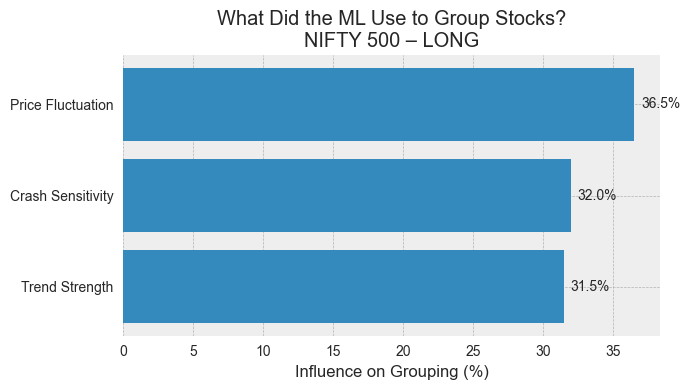


Running XAI for NIFTY 500 (BROAD)
Loaded NIFTY500 BROAD (2717 Days x 328 Stocks)


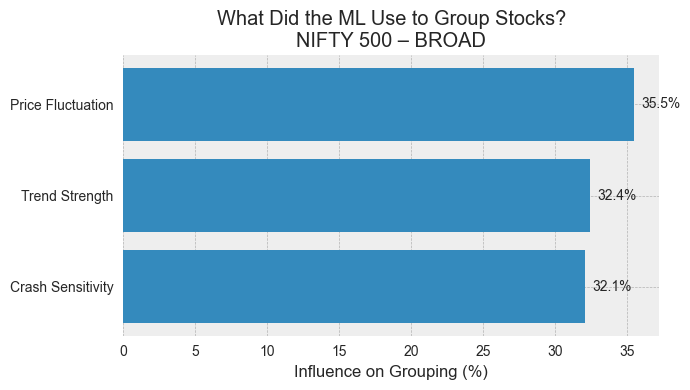


Running XAI for S&P 500 (LONG)
Loaded SP500 LONG (4779 Days x 432 Stocks)


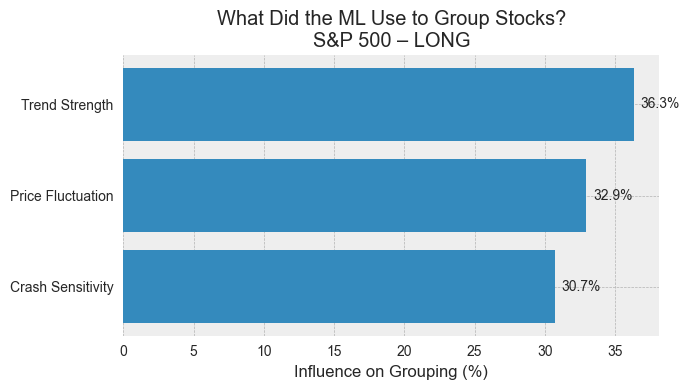


Running XAI for S&P 500 (BROAD)
Loaded SP500 BROAD (2765 Days x 469 Stocks)


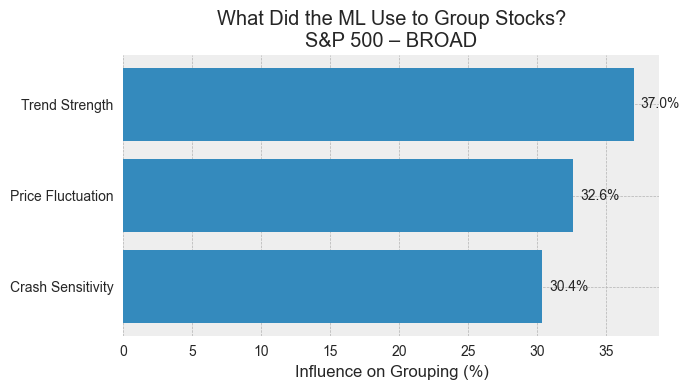

All universes processed.


In [44]:
# ==========================================
# CELL 4: RUN ALL 4 UNIVERSES
# ==========================================

universes = [
    ("nifty500", "long"),
    ("nifty500", "broad"),
    ("sp500", "long"),
    ("sp500", "broad")
]

comparison_results = {}

for market, cohort in universes:
    imp = generate_layman_xai(market, cohort, all_results)
    if imp is not None:
        comparison_results[(market, cohort)] = imp

print("All universes processed.")


S&P 500
--------------------------------------------------
First PC Variance: 39.40%
PCA–Market Correlation: 0.9984


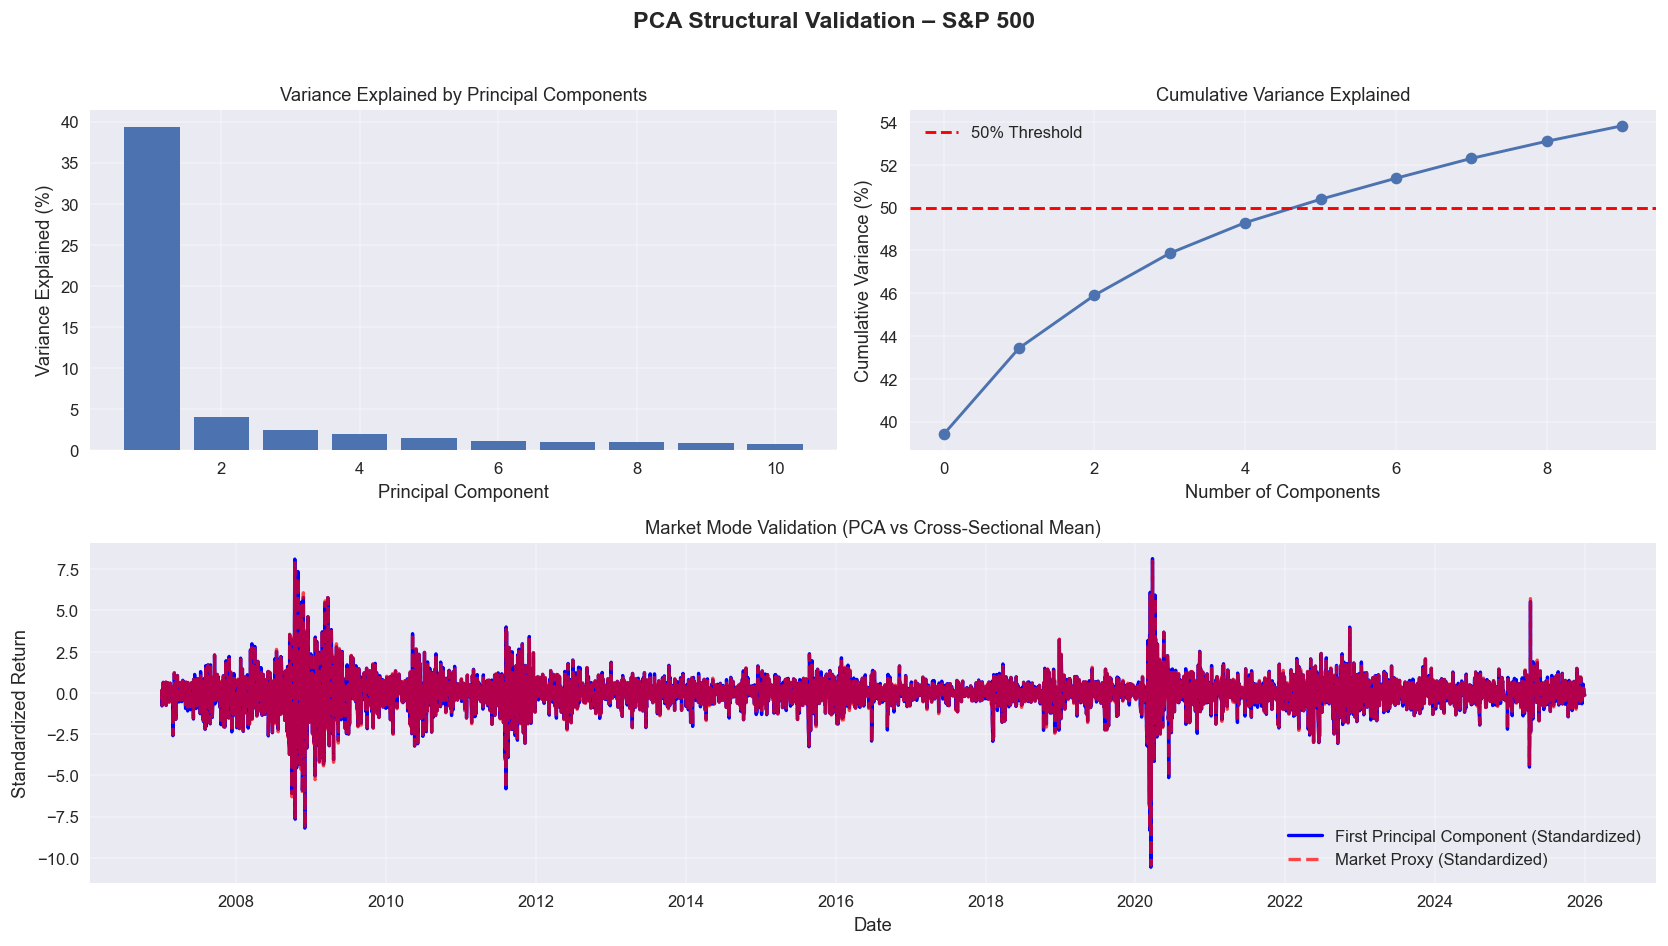


NIFTY 500
--------------------------------------------------
First PC Variance: 23.06%
PCA–Market Correlation: 0.9977


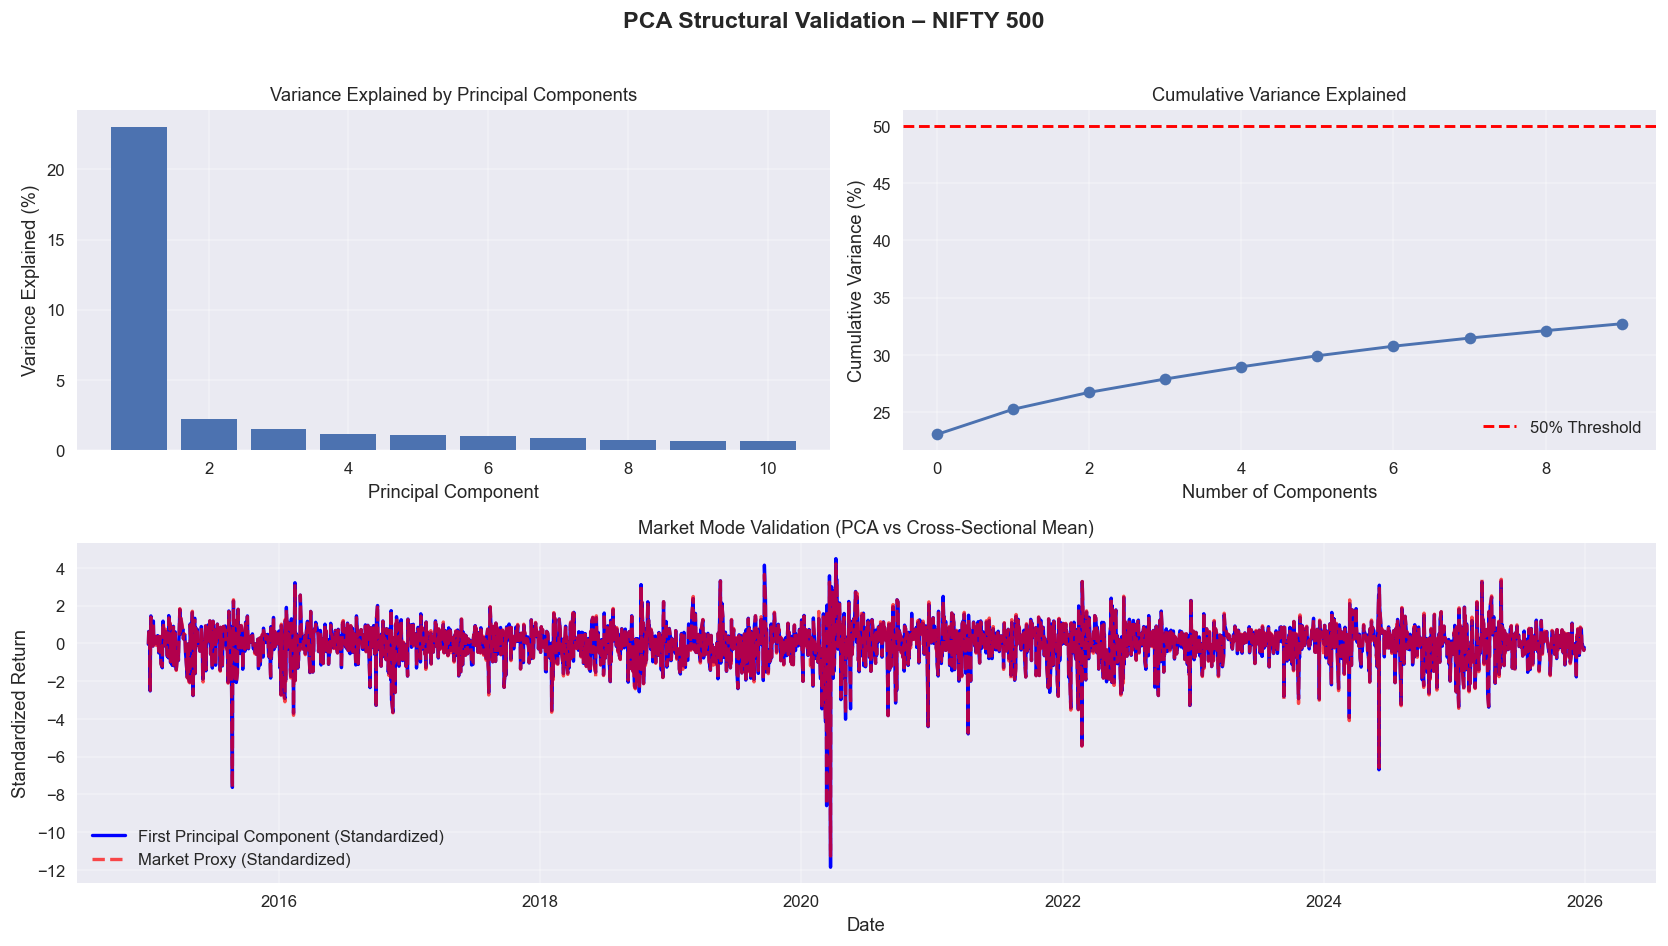

{'Market Universe': 'NIFTY 500',
 'Variance Explained by PC1 (%)': np.float64(23.06),
 'Correlation (PC1 vs Market Proxy)': np.float64(0.9977)}

In [ ]:
run_pca_validation(sp_long_returns, "S&P 500", show_plot=True)
run_pca_validation(nifty_broad_returns, "NIFTY 500", show_plot=True)

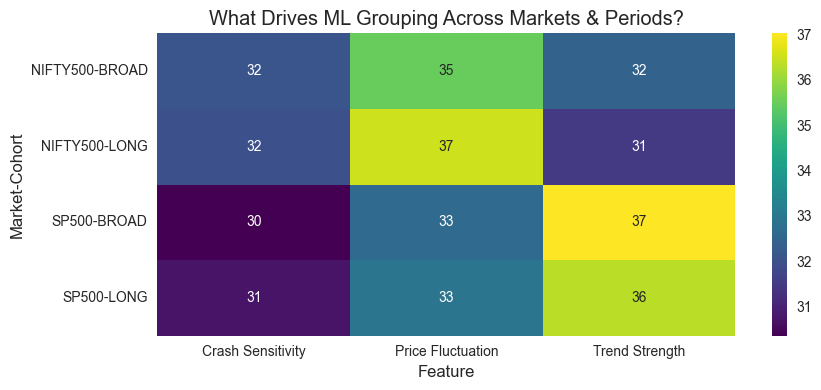

In [45]:
# ==========================================
# CELL 5: COMPARISON HEATMAP
# ==========================================

combined = []

for (market, cohort), df_imp in comparison_results.items():
    for _, row in df_imp.iterrows():
        combined.append({
            "Market": market.upper(),
            "Cohort": cohort.upper(),
            "Feature": row["Feature"],
            "Influence (%)": row["Influence (%)"]
        })

df_combined = pd.DataFrame(combined)

pivot_table = df_combined.pivot_table(
    index=["Market", "Cohort"],
    columns="Feature",
    values="Influence (%)"
)

plt.figure(figsize=(9,4))
sns.heatmap(pivot_table, annot=True, cmap="viridis")
plt.title("What Drives ML Grouping Across Markets & Periods?")
plt.tight_layout()
plt.show()

In [67]:
# ==========================================
# CELL: INTERPRETATION ENGINE
# ==========================================

def interpret_structural_results(pivot_table):

    print("\n" + "="*70)
    print("INTERPRETATION SUMMARY (AUTOMATED)")
    print("="*70)

    for idx, row in pivot_table.iterrows():

        market, cohort = idx
        dominant_feature = row.idxmax()
        dominance_value = row.max()

        print(f"\n {market} – {cohort}")
        print("-"*50)
        print(f"Dominant Driver: {dominant_feature} ({dominance_value:.1f}%)")

        # Layman explanation
        if dominant_feature == "Price Fluctuation":
            explanation = (
                "The AI mainly grouped stocks based on how much their prices move up and down."
            )

        elif dominant_feature == "Trend Strength":
            explanation = (
                "The AI mainly grouped stocks based on long-term price trends and momentum."
            )

        elif dominant_feature == "Crash Sensitivity":
            explanation = (
                "The AI mainly grouped stocks based on how sensitive they are during market declines."
            )

        else:
            explanation = "Structural grouping driver identified."

        print("Layman Interpretation:")
        print("→", explanation)

        # Academic interpretation
        print("\nDissertation-Ready Interpretation:")
        if dominant_feature == "Price Fluctuation":
            print(
                "Clustering is primarily volatility-driven, suggesting risk dispersion "
                "is the core structural segmentation mechanism in this market regime."
            )

        elif dominant_feature == "Trend Strength":
            print(
                "Clustering is predominantly momentum-driven, indicating that trend persistence "
                "forms the principal structural differentiation factor."
            )

        elif dominant_feature == "Crash Sensitivity":
            print(
                "Clustering is primarily driven by downside-risk behaviour, implying "
                "risk-asymmetry governs structural grouping."
            )

    print("\n" + "="*70)
    print("Comparative Structural Insight")
    print("="*70)

    grouped = pivot_table.groupby(level=0).mean()

    for market in grouped.index:
        dominant = grouped.loc[market].idxmax()
        print(f"{market} behaves as a '{dominant}' structured market.")


# Run interpretation
interpret_structural_results(pivot_table)


INTERPRETATION SUMMARY (AUTOMATED)

 NIFTY500 – BROAD
--------------------------------------------------
Dominant Driver: Price Fluctuation (35.5%)
Layman Interpretation:
→ The AI mainly grouped stocks based on how much their prices move up and down.

Dissertation-Ready Interpretation:
Clustering is primarily volatility-driven, suggesting risk dispersion is the core structural segmentation mechanism in this market regime.

 NIFTY500 – LONG
--------------------------------------------------
Dominant Driver: Price Fluctuation (36.5%)
Layman Interpretation:
→ The AI mainly grouped stocks based on how much their prices move up and down.

Dissertation-Ready Interpretation:
Clustering is primarily volatility-driven, suggesting risk dispersion is the core structural segmentation mechanism in this market regime.

 SP500 – BROAD
--------------------------------------------------
Dominant Driver: Trend Strength (37.0%)
Layman Interpretation:
→ The AI mainly grouped stocks based on long-term pri

In [66]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [50]:
import pandas as pd

# Long Cohort
nifty_long_returns = pd.read_parquet("../data_processed/nifty500_returns.parquet")
sp_long_returns = pd.read_parquet("../data_processed/sp500_returns.parquet")

# Broad Cohort (2015+)
nifty_broad_returns = pd.read_parquet("../data_processed/nifty500_2015_returns.parquet")
sp_broad_returns = pd.read_parquet("../data_processed/sp500_2015_returns.parquet")

print("NIFTY Long:", nifty_long_returns.shape)
print("NIFTY Broad:", nifty_broad_returns.shape)
print("S&P Long:", sp_long_returns.shape)
print("S&P Broad:", sp_broad_returns.shape)

NIFTY Long: (4691, 295)
NIFTY Broad: (2717, 328)
S&P Long: (4779, 432)
S&P Broad: (2765, 469)


In [51]:
# Long Cohort (2007–2026)
nifty_long_returns = pd.read_parquet("../data_processed/nifty500_returns.parquet")
sp_long_returns = pd.read_parquet("../data_processed/sp500_returns.parquet")

# Broad Cohort (2015–2026)
nifty_broad_returns = pd.read_parquet("../data_processed/nifty500_2015_returns.parquet")
sp_broad_returns = pd.read_parquet("../data_processed/sp500_2015_returns.parquet")

print("Loaded Successfully")

Loaded Successfully


In [52]:
def plot_pca_validation(first_pc_std, market_std, explained_variance, universe_name):

    plt.style.use('seaborn-v0_8')

    fig = plt.figure(figsize=(14,8), dpi=120)
    fig.suptitle(f"PCA Structural Validation – {universe_name}",
                 fontsize=14,
                 fontweight='bold')

    # -------- Variance Bar --------
    ax1 = plt.subplot2grid((2,2),(0,0))
    ax1.bar(range(1,11), explained_variance[:10]*100)
    ax1.set_title("Variance Explained by Principal Components", fontsize=11)
    ax1.set_xlabel("Principal Component")
    ax1.set_ylabel("Variance Explained (%)")
    ax1.grid(alpha=0.3)

    # -------- Cumulative --------
    ax2 = plt.subplot2grid((2,2),(0,1))
    ax2.plot(np.cumsum(explained_variance[:10])*100, marker='o')
    ax2.axhline(50, linestyle='--', color='red', label="50% Threshold")
    ax2.set_title("Cumulative Variance Explained", fontsize=11)
    ax2.set_xlabel("Number of Components")
    ax2.set_ylabel("Cumulative Variance (%)")
    ax2.legend()
    ax2.grid(alpha=0.3)

    # -------- Market Mode --------
    ax3 = plt.subplot2grid((2,2),(1,0), colspan=2)
    ax3.plot(first_pc_std.index, first_pc_std,
             label="First Principal Component (Standardized)",
             linewidth=2, color='blue')

    ax3.plot(market_std.index, market_std,
             linestyle='--',
             label="Market Proxy (Standardized)",
             linewidth=2, color='red', alpha=0.7)

    ax3.set_title("Market Mode Validation (PCA vs Cross-Sectional Mean)", fontsize=11)
    ax3.set_xlabel("Date")
    ax3.set_ylabel("Standardized Return")
    ax3.legend()
    ax3.grid(alpha=0.3)

    plt.tight_layout(rect=[0,0,1,0.96])
    plt.show()

In [53]:
def run_pca_validation(returns: pd.DataFrame, universe_name: str, show_plot=False):

    # Keep stocks with at least 90% valid data
    returns = returns.dropna(axis=1, thresh=int(0.9 * len(returns)))
    returns = returns.fillna(0)

    if returns.shape[1] < 5:
        print(f"{universe_name} has insufficient valid columns.")
        return None

    scaler = StandardScaler()
    scaled = scaler.fit_transform(returns)

    pca = PCA(n_components=10)
    components = pca.fit_transform(scaled)

    explained_variance = pca.explained_variance_ratio_

    # Convert PCA factor to Series with proper index
    first_pc = pd.Series(
        components[:, 0],
        index=returns.index,
        name="PCA Factor 1"
    )

    market_proxy = returns.mean(axis=1)

    # Standardize both for visual comparison
    first_pc_std = (first_pc - first_pc.mean()) / first_pc.std()
    market_std = (market_proxy - market_proxy.mean()) / market_proxy.std()

    corr = first_pc_std.corr(market_std)

    print(f"\n{universe_name}")
    print("-" * 50)
    print(f"First PC Variance: {explained_variance[0]*100:.2f}%")
    print(f"PCA–Market Correlation: {corr:.4f}")

    if show_plot:
        plot_pca_validation(first_pc_std, market_std, explained_variance, universe_name)

    return {
        "Market Universe": universe_name,
        "Variance Explained by PC1 (%)": round(explained_variance[0]*100, 2),
        "Correlation (PC1 vs Market Proxy)": round(corr, 4)
    }

In [54]:
summary_results = []

summary_results.append(run_pca_validation(nifty_long_returns, "NIFTY 500 (Long)"))
summary_results.append(run_pca_validation(nifty_broad_returns, "NIFTY 500 (Broad)"))
summary_results.append(run_pca_validation(sp_long_returns, "S&P 500 (Long)"))
summary_results.append(run_pca_validation(sp_broad_returns, "S&P 500 (Broad)"))

summary_df = pd.DataFrame(summary_results)

summary_df


NIFTY 500 (Long)
--------------------------------------------------
First PC Variance: 23.74%
PCA–Market Correlation: 0.9985

NIFTY 500 (Broad)
--------------------------------------------------
First PC Variance: 23.06%
PCA–Market Correlation: 0.9977

S&P 500 (Long)
--------------------------------------------------
First PC Variance: 39.40%
PCA–Market Correlation: 0.9984

S&P 500 (Broad)
--------------------------------------------------
First PC Variance: 36.10%
PCA–Market Correlation: 0.9980


,Market Universe,Variance Explained by PC1 (%),Correlation (PC1 vs Market Proxy)
0,NIFTY 500 (Long),23.74,0.9985
1,NIFTY 500 (Broad),23.06,0.9977
2,S&P 500 (Long),39.40,0.9984
3,S&P 500 (Broad),36.10,0.9980



S&P 500
--------------------------------------------------
First PC Variance: 39.40%
PCA–Market Correlation: 0.9984


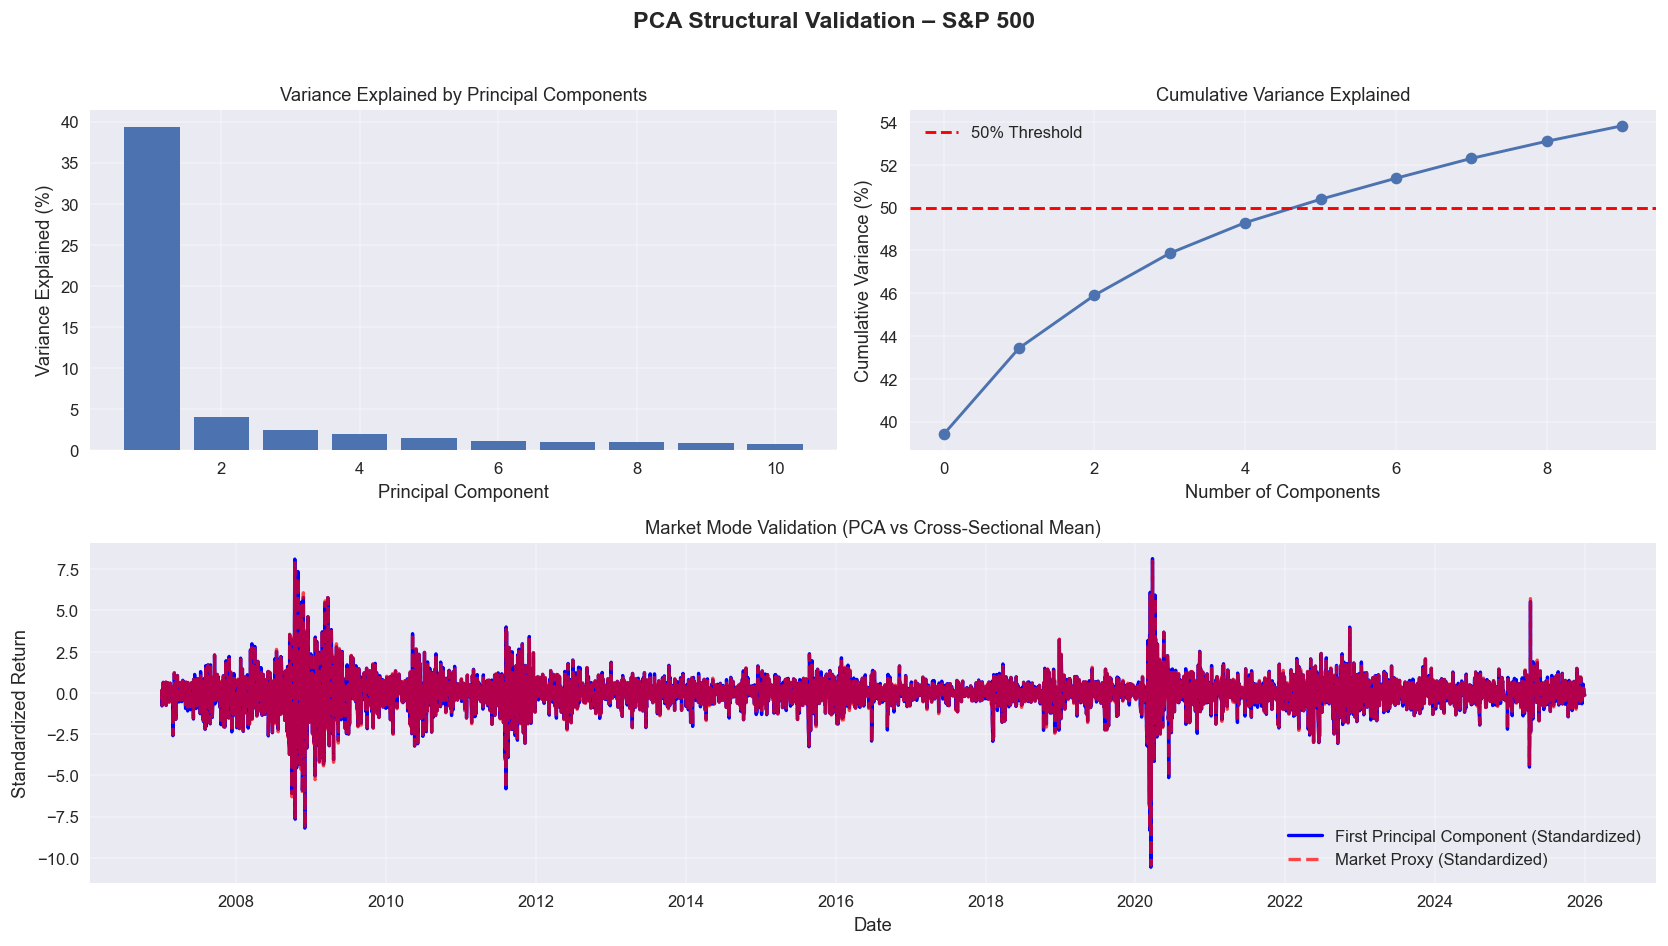


NIFTY 500
--------------------------------------------------
First PC Variance: 23.06%
PCA–Market Correlation: 0.9977


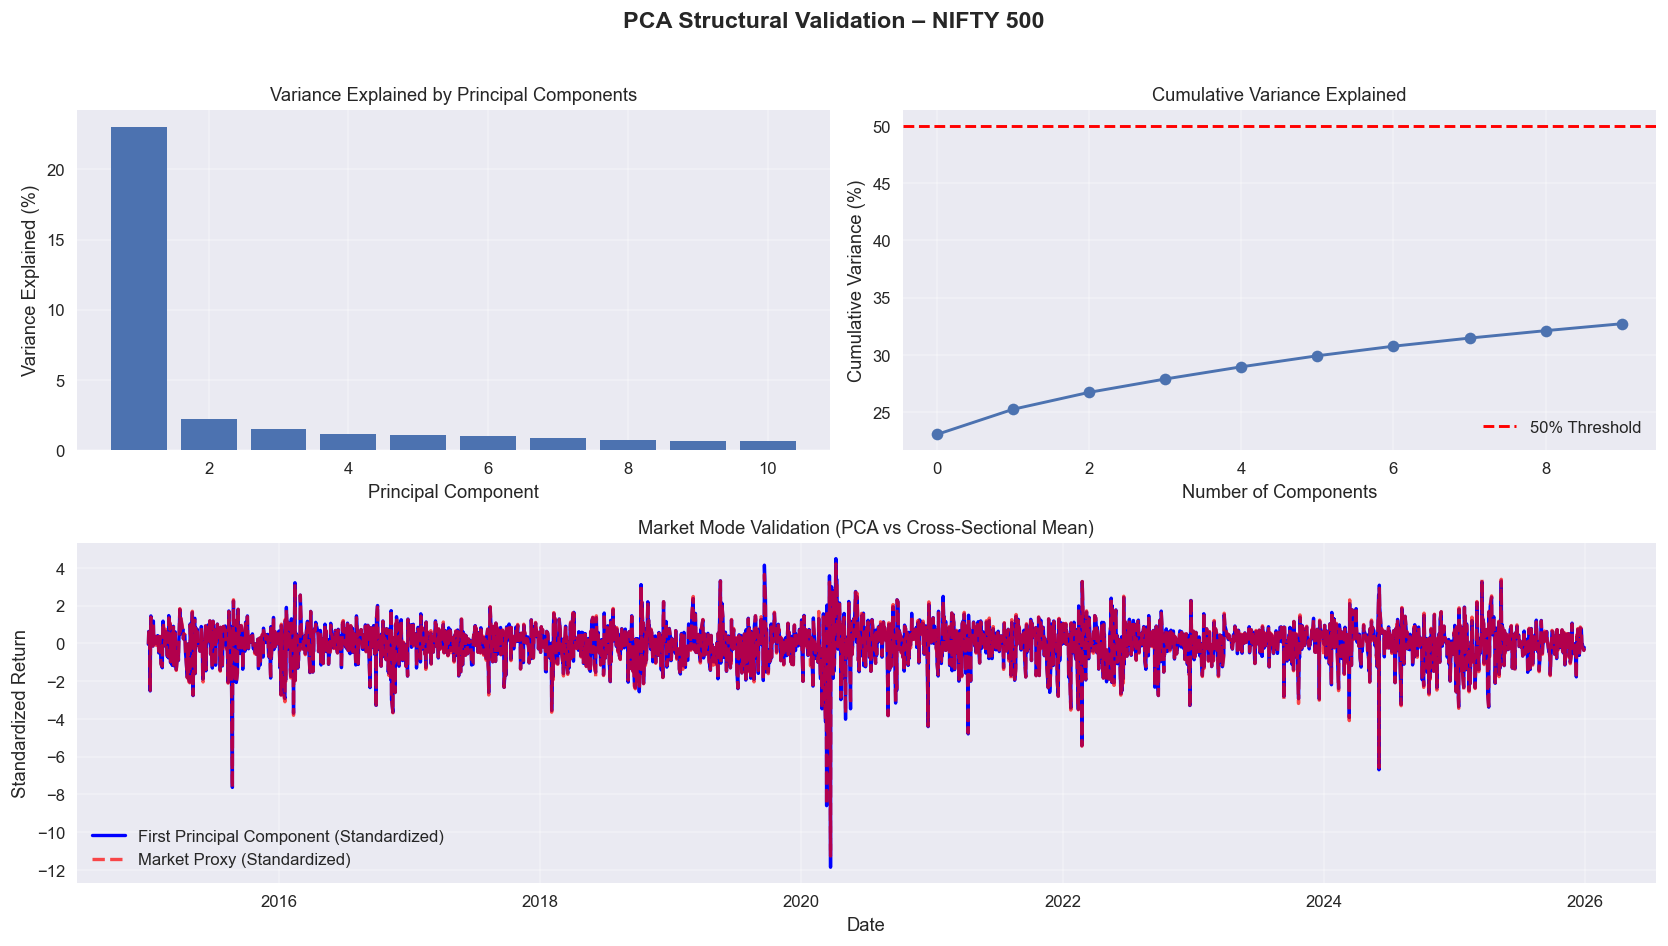

{'Market Universe': 'NIFTY 500',
 'Variance Explained by PC1 (%)': np.float64(23.06),
 'Correlation (PC1 vs Market Proxy)': np.float64(0.9977)}

In [55]:
run_pca_validation(sp_long_returns, "S&P 500", show_plot=True)
run_pca_validation(nifty_broad_returns, "NIFTY 500", show_plot=True)

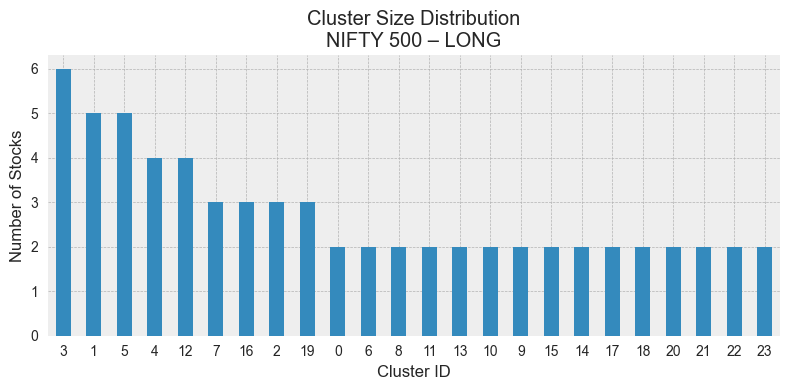

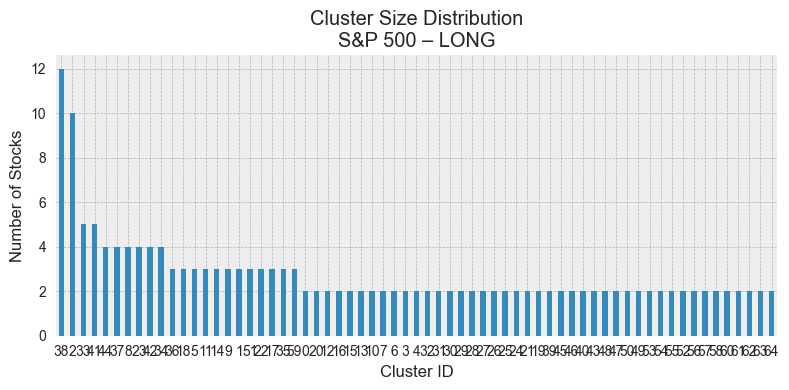

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("bmh")

# -----------------------------
# LOAD CLUSTER DATA
# -----------------------------
project_root = Path.cwd().parent
DATA_PROCESSED = project_root / "data_processed"

all_pairs = pd.read_csv(DATA_PROCESSED / "all_ml_pairs.csv")

# -----------------------------
# FUNCTION TO PLOT CLUSTER SIZE
# -----------------------------
def plot_cluster_distribution(market_name, cohort_name):

    subset = all_pairs[
        (all_pairs["Market"] == market_name) &
        (all_pairs["Cohort"] == cohort_name)
    ]

    if subset.empty:
        print("No data.")
        return

    cluster_sizes = []

    for cluster_id, group in subset.groupby("Cluster_ID"):

        members = sorted(
            set(group["Ticker1"])
            |
            set(group["Ticker2"])
        )

        cluster_sizes.append({
            "Cluster_ID": cluster_id,
            "Size": len(members)
        })

    cluster_df = pd.DataFrame(cluster_sizes)

    cluster_df = cluster_df.sort_values(
        "Size",
        ascending=False
    )

    plt.figure(figsize=(8,4))

    plt.bar(
        cluster_df["Cluster_ID"].astype(str),
        cluster_df["Size"]
    )

    plt.title(
        f"Cluster Size Distribution\n{market_name} ({cohort_name})"
    )

    plt.xlabel("Cluster")

    plt.ylabel("Unique Stocks")

    plt.tight_layout()

    plt.show()

    return cluster_df
# -----------------------------
# RUN FOR LONG COHORTS
# -----------------------------
nifty_long_counts = plot_cluster_distribution("NIFTY 500", "long")
sp_long_counts = plot_cluster_distribution("S&P 500", "long")

In [ ]:
import pandas as pd
from pathlib import Path

# -----------------------------
# LOAD DATA
# -----------------------------
project_root = Path.cwd().parent
DATA_PROCESSED = project_root / "data_processed"

all_pairs = pd.read_csv(DATA_PROCESSED / "all_ml_pairs.csv")

# -----------------------------
# BUILD SUMMARY TABLE
# -----------------------------
summary_rows = []

for market in all_pairs["Market"].unique():
    for cohort in all_pairs["Cohort"].unique():

        subset = all_pairs[
            (all_pairs["Market"] == market) &
            (all_pairs["Cohort"] == cohort)
        ]

        if subset.empty:
            continue

        members = set(subset["Ticker1"]) | set(subset["Ticker2"])
        total_stocks = len(members)

        cluster_sizes = []
        
        for cluster_id, group in subset.groupby("Cluster_ID"):
            members = set(group["Ticker1"]) | set(group["Ticker2"])
            cluster_sizes.append(len(members))
        num_clusters = len(cluster_sizes)
        grouped_stocks = sum(cluster_sizes)
        noise_stocks = 0

summary_table = pd.DataFrame(summary_rows)

summary_table = summary_table.sort_values(
    ["Market Universe", "Cohort"]
).reset_index(drop=True)

print("\nOPTICS Clustering Summary\n")
display(summary_table)


OPTICS Clustering Summary



,Market Universe,Cohort,Identified Clusters,Stocks Grouped,Noise Stocks (Cluster -1)
0,NIFTY 500,broad,26,76,0
1,NIFTY 500,long,24,66,0
2,S&P 500,broad,82,225,0
3,S&P 500,long,65,178,0


In [58]:
all_pairs["Cluster_ID"].value_counts().head(10)

Cluster_ID
2     18
38    17
18    16
5     15
7     15
0     14
9     14
3     14
4     14
1     13
Name: count, dtype: int64